In [1]:
import joblib
import h5py
import numpy as np
from utils import save, load
from library import *
import gc
from continuous_process_library_terms import *
from commons_identify_models import *
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
#import xarray 
#import xarray as xr
import dataclasses
import time
jax.config.update("jax_enable_x64", True)
import numpy as np
import os, joblib
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from numpy.polynomial.chebyshev import chebvander

import contextlib
import joblib
from tqdm import tqdm

@contextlib.contextmanager
def tqdm_joblib(tqdm_object):
    """Context manager to patch joblib to report into tqdm progress bar given as argument"""
    class TqdmBatchCompletionCallback(joblib.parallel.BatchCompletionCallBack):
        def __call__(self, *args, **kwargs):
            tqdm_object.update(n=self.batch_size)
            return super().__call__(*args, **kwargs)

    old_batch_callback = joblib.parallel.BatchCompletionCallBack
    joblib.parallel.BatchCompletionCallBack = TqdmBatchCompletionCallback
    try:
        yield tqdm_object
    finally:
        joblib.parallel.BatchCompletionCallBack = old_batch_callback
        tqdm_object.close()

/storage/home/hcoda1/2/ashelestov3/.conda/envs/SPIDER/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# --- NEW CELL (Call this 'Cell 2 - New') ---
# Run this cell INSTEAD of the old cells 2, 3, and 4.

print("Loading preprocessed arrays from .npz file...")

# Path to the file you just saved
load_path = '/storage/scratch1/2/ashelestov3/preprocessed_paper_data.npz'

# Load the data from the .npz file
data = np.load(load_path)
print("loaded - processing")
# Re-create your variables from the saved data
V = data['U']
U = data['V']
P = data['P']
B = data['B']
W = data['W']
x = data['x']
y = data['y']
t = data['t']
print(y,y[1]-y[0],y[201]-y[200])
y=np.linspace(0,1,num=1536)

print(y,y[1]-y[0],y[201]-y[200])
del(data)
# IMPORTANT: You must also re-define the parameters from your old Cell 3,
# as the rest of your notebook depends on them.
size_x = 4096
size_y = 1536
inner_steps = 1
outer_steps = t.shape[0]

Lx =  4
Ly = 1
Nx = size_x
Ny = size_y
Nt = outer_steps
# Calculate dx/dy from the actual new coordinate arrays
dx = x[1] - x[0]
dy = y[1] - y[0]
print(f"Updated dx: {dx}, dy: {dy}")
Lt = t[-1]-t[0]
dt = Lt/Nt
Rayleigh = 1e8
Prandtl = 1
kappa = (Rayleigh * Prandtl)**(-1/2)
print("Done loading!")
print("U shape:", U.shape)
print("P shape:", P.shape)
print("dx:", dx)
print("dt:", dt)
print(dy-Ly / (Ny - 1))

Loading preprocessed arrays from .npz file...
loaded - processing
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
[0.00000000e+00 6.51465798e-04 1.30293160e-03 ... 9.98697068e-01
 9.99348534e-01 1.00000000e+00] 0.0006514657980456026 0.0006514657980456195
Updated dx: 0.0009765625, dy: 0.0006514657980456026
Done loading!
U shape: (4096, 1536, 101)
P shape: (4096, 1536, 101)
dx: 0.0009765625
dt: 2.380099009900647e-05
0.0


In [31]:
import builtins
import jax
import jax.numpy as jnp
from functools import partial

# --- REPLACEMENT FILTERING FUNCTIONS (Adapted for 2D: x, y) ---

def _sigma_from_delta(delta):
    return delta / jnp.sqrt(12.0)

def _trap_weights_nonuniform(x):
    dx = jnp.diff(x)
    w_mid = 0.5 * (dx[:-1] + dx[1:])
    w0 = 0.5 * dx[0]
    wn = 0.5 * dx[-1]
    return jnp.concatenate([jnp.array([w0]), w_mid, jnp.array([wn])])

@partial(jax.jit, static_argnums=(4,))
def _convolve1d_nonuniform_gaussian(arr, coord, delta, alpha, axis):
    sigma = _sigma_from_delta(delta)
    R = alpha * delta
    n = coord.size

    # Trapezoidal weights
    wq = _trap_weights_nonuniform(coord)

    # Move axis to front for easy processing
    a = jnp.moveaxis(arr, axis, 0)  # shape: (n, ...)

    # Build the pairwise distance matrix (n, n)
    dists = coord[:, None] - coord[None, :]
    kernel = jnp.exp(-0.5 * (dists / sigma)**2)
    mask = jnp.abs(dists) <= R
    kernel = kernel * mask

    # Weighted kernel
    weighted_kernel = kernel * wq[None, :]  # shape (n, n)
    norm = weighted_kernel.sum(axis=1, keepdims=True)
    weights = weighted_kernel / norm  # normalize rows

    # Apply weights: shape (n, ...) = (n, n) @ (n, ...)
    out = jnp.tensordot(weights, a, axes=(1, 0))  # shape (n, ...)

    return jnp.moveaxis(out, 0, axis)

def trim_edges_jax(array, x=None, y=None, delta=0.0):
    """
    Trims `delta` distance from the edges of a JAX array and coordinates.
    Adapted for 2D inputs (x, y).
    """
    def get_valid_indices(coord):
        return jnp.where((coord >= coord[0] + delta) & (coord <= coord[-1] - delta))[0]

    slices = []
    new_coords = []

    # Iterate over x and y only (matching array shape order)
    for coord in (x, y):
        if coord is not None:
            idx = get_valid_indices(coord)
            if len(idx) > 0:
                start = int(idx[0])
                end = int(idx[-1]) + 1
                slices.append(builtins.slice(start, end))
                new_coords.append(coord[start:end])
            else:
                # Fallback if delta trims everything
                slices.append(builtins.slice(None))
                new_coords.append(coord)
        else:
            slices.append(builtins.slice(None))
            new_coords.append(None)

    # Trim array using tuple of slices
    # The array has a time dimension at the end, keep it full
    slices.append(builtins.slice(None)) 
    trimmed_array = array[tuple(slices)]

    return trimmed_array, *new_coords

def gaussian_filter_2d_finite_support_over_time(field, x, y, delta, alpha):
    """
    Applies Gaussian filter along x, y axes at each time slice.
    field: (Nx, Ny, Nt)
    """
    print(field.shape)
    dx = float(x[1] - x[0])
    dy = float(y[1] - y[0])
    
    # ADDED: Pre-calculate constant kernels
    kernel_x = _get_uniform_gaussian_kernel(dx, delta, alpha)
    kernel_y = _get_uniform_gaussian_kernel(dy, delta, alpha)
    def filter_single_timestep(f):
        # f has shape (Nx, Ny)
        print(f.shape)
        f = _convolve1d_uniform_edge_padded(f, kernel_x, axis=0)
        f = _convolve1d_uniform_edge_padded(f, kernel_y, axis=1)
        
        # Return the full 2D frame, NOT f[..., 0]
        return f

    # Use JAX vmap to vectorise over the Time axis (axis 2 in your data)
    # field shape is (Nx, Ny, Nt), so we map over axis 2
    result = jax.vmap(filter_single_timestep, in_axes=2, out_axes=2)(field)
    
    # Trim edges
    field_out, xp, yp = trim_edges_jax(result, x, y, delta=(alpha * (delta+1)))
    
    return field_out, xp, yp

def _get_uniform_gaussian_kernel(dx, delta, alpha):
    sigma = delta / jnp.sqrt(12.0)
    R = alpha * delta
    r_points = int(jnp.ceil(R / dx))
    xs = jnp.arange(-r_points, r_points + 1) * dx
    kernel = jnp.exp(-0.5 * (xs / sigma)**2)
    return kernel / jnp.sum(kernel)

@partial(jax.jit, static_argnums=(2,))
def _convolve1d_uniform_edge_padded(arr, kernel, axis):
    pad_width = len(kernel) // 2
    if axis == 0:
        padded = jnp.pad(arr, ((pad_width, pad_width), (0, 0)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded.T).T
    elif axis == 1:
        padded = jnp.pad(arr, ((0, 0), (pad_width, pad_width)), mode='edge')
        conv_fn = jax.vmap(lambda x: jnp.convolve(x, kernel, mode='valid'))
        return conv_fn(padded)
    
    

# --- EXECUTION ---

# Define parameters based on your notebook variables
delta = 50 * dx
print(delta)
alpha = 3

print("Starting JAX filtering...")

# Convert numpy arrays to JAX arrays for processing
u_jax = jnp.array(U)
x_jax = jnp.array(x)
y_jax = jnp.array(y)
print(u_jax.shape)
# Run the filter
# Note: No 'z' is passed because your data is 2D
u_filt, xp, yp = gaussian_filter_2d_finite_support_over_time(u_jax, x_jax, y_jax, delta, alpha)

# If you need to filter other variables (V, P, B, W):
# v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
# p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)

print("Filtering complete.")
print("New shape:", u_filt.shape)

0.048828125
Starting JAX filtering...
(4096, 1536, 101)
(4096, 1536, 101)
(4096, 1536)
Filtering complete.
New shape: (4096, 1536, 101)


In [32]:
# --- STEP 2: Filter Remaining Variables & Calculate Stresses ---

print("Filtering remaining variables...")

# 1. Filter the primary variables (V, P, B, W)
# We use the same parameters (delta, alpha) and coordinate arrays as Step 1.
v_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V), x_jax, y_jax, delta, alpha)
p_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(P), x_jax, y_jax, delta, alpha)
b_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(B), x_jax, y_jax, delta, alpha)
w_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(W), x_jax, y_jax, delta, alpha)

# 2. Filter the product terms for Reynolds Stresses
# Mathematical requirement: Filter the products (uu, vv, uv) before subtracting the means.
print("Filtering product terms for Tau...")
uu_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U**2), x_jax, y_jax, delta, alpha)
vv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V**2), x_jax, y_jax, delta, alpha)
uv_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U*V), x_jax, y_jax, delta, alpha)

# 3. Calculate Stresses (Tau)
# Formula: tau_ij = filtered(u_i * u_j) - filtered(u_i) * filtered(u_j)

# Convert JAX arrays back to standard Numpy arrays for final assembly
u_filt_np = np.array(u_filt)
v_filt_np = np.array(v_filt)
uu_filt_np = np.array(uu_filt)
vv_filt_np = np.array(vv_filt)
uv_filt_np = np.array(uv_filt)

tau_xx = uu_filt_np - (u_filt_np**2)
tau_yy = vv_filt_np - (v_filt_np**2)
tau_xy = uv_filt_np - (u_filt_np * v_filt_np)

# 4. Stack results to match your original notebook structure
print("Stacking final arrays...")

# Create u_bar vector: Shape (Nx, Ny, Nt, 2)
u_bar = np.stack([u_filt_np, v_filt_np], axis=3)

# Create Tau tensor: Shape (Nx, Ny, Nt, 2, 2)
# Structure: [[tau_xx, tau_xy], [tau_xy, tau_yy]]
row1 = np.stack([tau_xx, tau_xy], axis=3)
row2 = np.stack([tau_xy, tau_yy], axis=3)
tau = np.stack([row1, row2], axis=4)

# 5. Finalize other fields
p_filt = np.array(p_filt)
b_filt = np.array(b_filt)
w_filt = np.array(w_filt)

# Update coordinate arrays to the trimmed versions returned by the filter
x = np.array(xp)
y = np.array(yp)

print("Step 2 Complete.")
print(f"Final shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}")

Filtering remaining variables...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Filtering product terms for Tau...
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
Stacking final arrays...
Step 2 Complete.
Final shapes -> u_bar: (4096, 1536, 101, 2), tau: (4096, 1536, 101, 2, 2)


In [33]:
print("filtering product terms for phi")

ub_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(U * B), x_jax, y_jax, delta, alpha)
vb_filt, _, _ = gaussian_filter_2d_finite_support_over_time(jnp.array(V * B), x_jax, y_jax, delta, alpha)

ub_filt_np = np.array(ub_filt)
vb_filt_np = np.array(vb_filt)

phi_x = ub_filt_np - (u_filt_np * b_filt)
phi_y = vb_filt_np - (v_filt_np * b_filt)

print("stacking")

phi = np.stack([phi_x, phi_y], axis=3)

print(f"Final shape -> phi: {phi.shape}")

filtering product terms for phi
(4096, 1536, 101)
(4096, 1536)
(4096, 1536, 101)
(4096, 1536)
stacking
Final shape -> phi: (4096, 1536, 101, 2)


In [34]:
u_bar=u_bar[50:-50,50:-50,:,:]
tau=tau[50:-50,50:-50,:,:,:]
p_filt=p_filt[50:-50,50:-50,:]
b_filt=b_filt[50:-50,50:-50,:]
w_filt=w_filt[50:-50,50:-50,:]
phi=phi[50:-50,50:-50,:,:]
print(f"Final-er shapes -> u_bar: {u_bar.shape}, tau: {tau.shape}, phi: {phi.shape}")

Final-er shapes -> u_bar: (3996, 1436, 101, 2), tau: (3996, 1436, 101, 2, 2), phi: (3996, 1436, 101, 2)


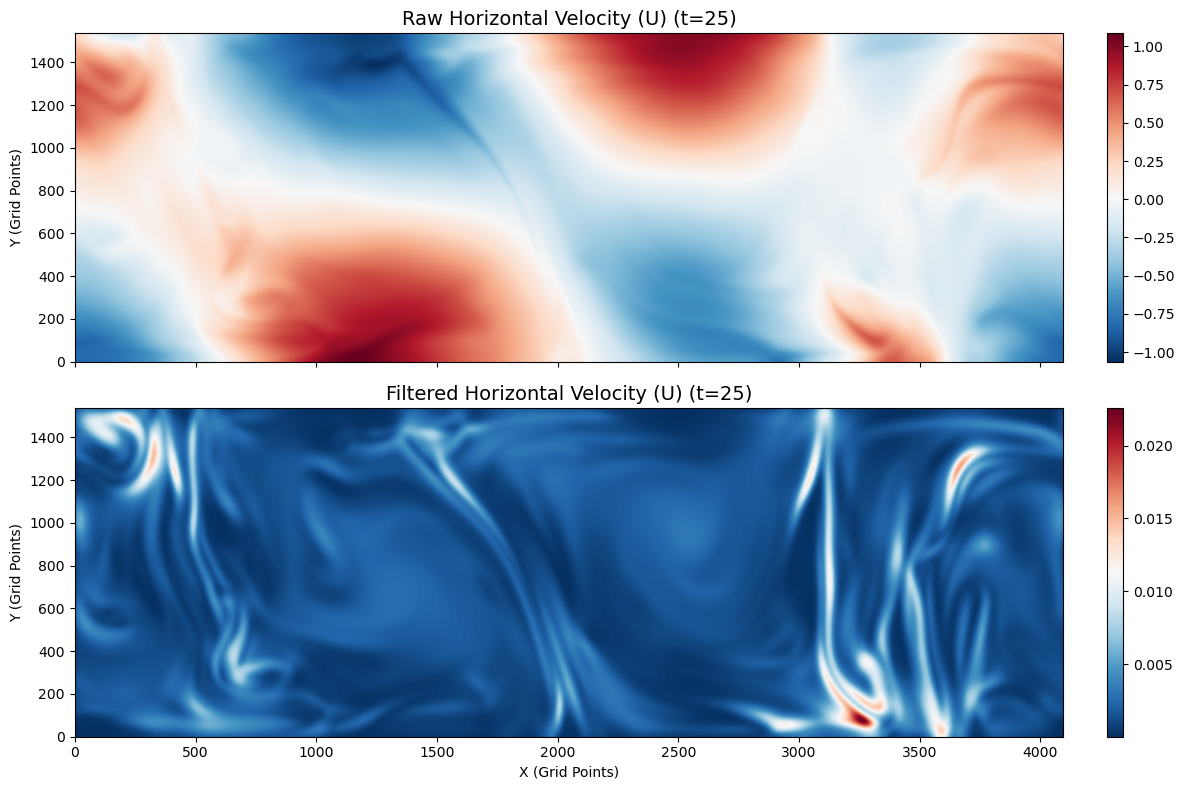

Zooming in on a small section...


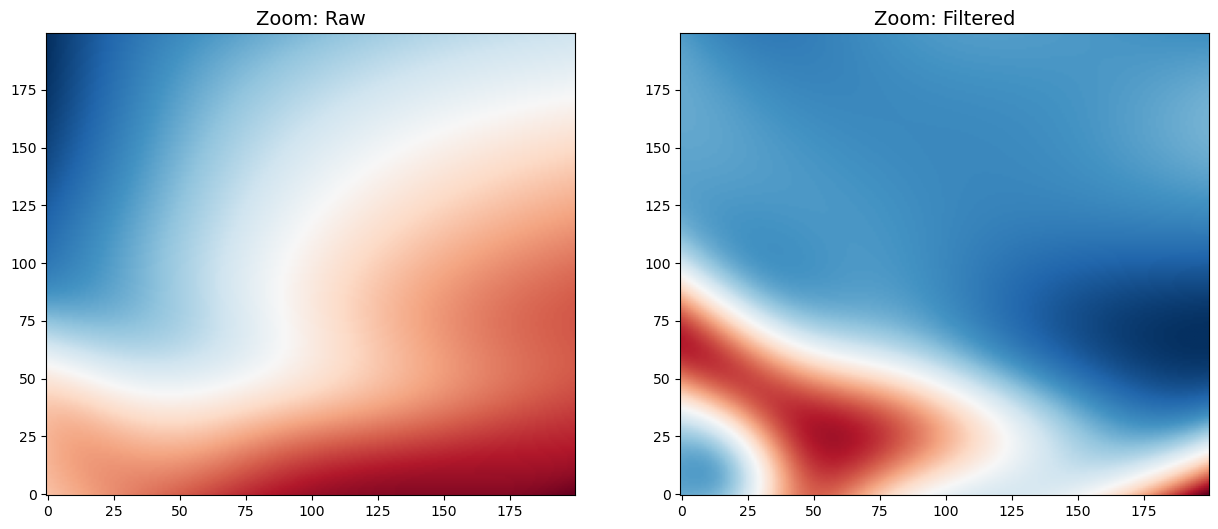

In [35]:
import matplotlib.pyplot as plt

# === Parameters ===
field_name = 'u'      # Choose: 'u', 'v', 'p', 'b', or 'w'
time_step_idx = 25    # Choose a timestep to visualize (e.g., 50)
cmap = 'RdBu_r'       # Colormap (Red-Blue is good for velocity/divergence)

# === Select Data ===
if field_name == 'u':
    raw_data = U[:, :, time_step_idx]
    filt_data = tau_xx[:, :, time_step_idx] + tau_yy[:, :, time_step_idx]
    title_txt = "Horizontal Velocity (U)"
elif field_name == 'v':
    raw_data = V[:, :, time_step_idx]
    filt_data = v_filt[:, :, time_step_idx]
    title_txt = "Vertical Velocity (V)"
elif field_name == 'b':
    raw_data = B[:, :, time_step_idx]
    filt_data = b_filt[:, :, time_step_idx]
    title_txt = "Buoyancy (B)"
elif field_name == 'p':
    raw_data = P[:, :, time_step_idx]
    filt_data = p_filt[:, :, time_step_idx]
    title_txt = "Pressure (P)"
elif field_name == 'w':
    raw_data = W[:, :, time_step_idx]
    filt_data = w_filt[:, :, time_step_idx]
    title_txt = "Vorticity (W)"

# === Plotting ===
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot Raw
# We transpose (.T) so that X is horizontal and Y is vertical
im1 = axes[0].imshow(raw_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title(f"Raw {title_txt} (t={time_step_idx})", fontsize=14)
axes[0].set_ylabel("Y (Grid Points)")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Plot Filtered
im2 = axes[1].imshow(filt_data.T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title(f"Filtered {title_txt} (t={time_step_idx})", fontsize=14)
axes[1].set_ylabel("Y (Grid Points)")
axes[1].set_xlabel("X (Grid Points)")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# === Optional: Zoom in to see the smoothing ===
# Use this to see the pixel-level difference
print("Zooming in on a small section...")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Zoom slice
ys, ye = 100, 300  # Y-slice
xs, xe = 1000, 1200 # X-slice

im3 = axes[0].imshow(raw_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[0].set_title("Zoom: Raw", fontsize=14)

im4 = axes[1].imshow(filt_data[xs:xe, ys:ye].T, origin='lower', cmap=cmap, aspect='auto')
axes[1].set_title("Zoom: Filtered", fontsize=14)

plt.show()

Calculating Continuity Residuals (Divergence)...
Raw Divergence      - Mean: 2.291656e-04, Max: 4.623640e-02
Filtered Divergence - Mean: 2.504205e-04, Max: 8.139378e-02


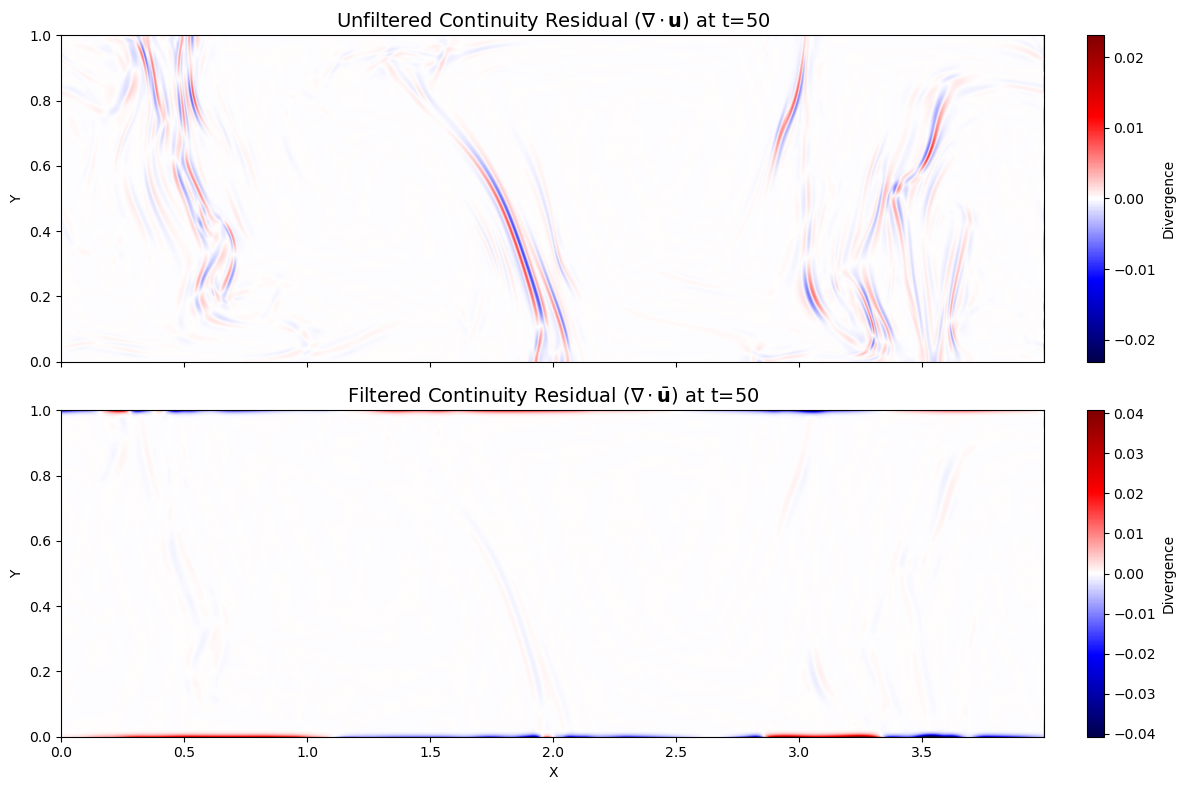

In [36]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residuals (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(U_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(V_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw
extent_raw = [x[0], x[-1], y[0], y[-1]]

# --- 2. Filtered Divergence ---
# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays
dx_filt = float(xp[1] - xp[0])
dy_filt = float(yp[1] - yp[0])

u_filt_t = u_bar[:, :, t_idx,0]
v_filt_t = u_bar[:, :, t_idx,1]

du_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)
dv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)
div_filt = du_dx_filt + dv_dy_filt
extent_filt = [xp[0], xp[-1], yp[0], yp[-1]]

print(f"Raw Divergence      - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Filtered Divergence - Mean: {np.mean(np.abs(div_filt)):.6e}, Max: {np.max(np.abs(div_filt)):.6e}")

# --- 3. 2x1 Plotting ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw)) * 0.5 
v_limit_filt = np.max(np.abs(div_filt)) * 0.5

# Plot Raw
im1 = axes[0].imshow(
    div_raw.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_raw,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)
axes[0].set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
axes[0].set_ylabel("Y")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="Divergence")

# Plot Filtered
im2 = axes[1].imshow(
    div_filt.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_filt,
    vmax=v_limit_filt
)
axes[1].set_title(f"Filtered Continuity Residual ($\\nabla \\cdot \\bar{{\\mathbf{{u}}}}$) at t={t_idx}", fontsize=14)
axes[1].set_ylabel("Y")
axes[1].set_xlabel("X")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Divergence")

plt.tight_layout()
plt.show()

Calculating Continuity Residuals (Divergence)...
Raw Divergence (Full) - Mean: 1.545702e+00, Max: 1.305804e+01
Filtered Divergence   - Mean: 1.925837e-02, Max: 3.286314e+00
Difference            - Mean: 1.552470e+00, Max: 1.305810e+01


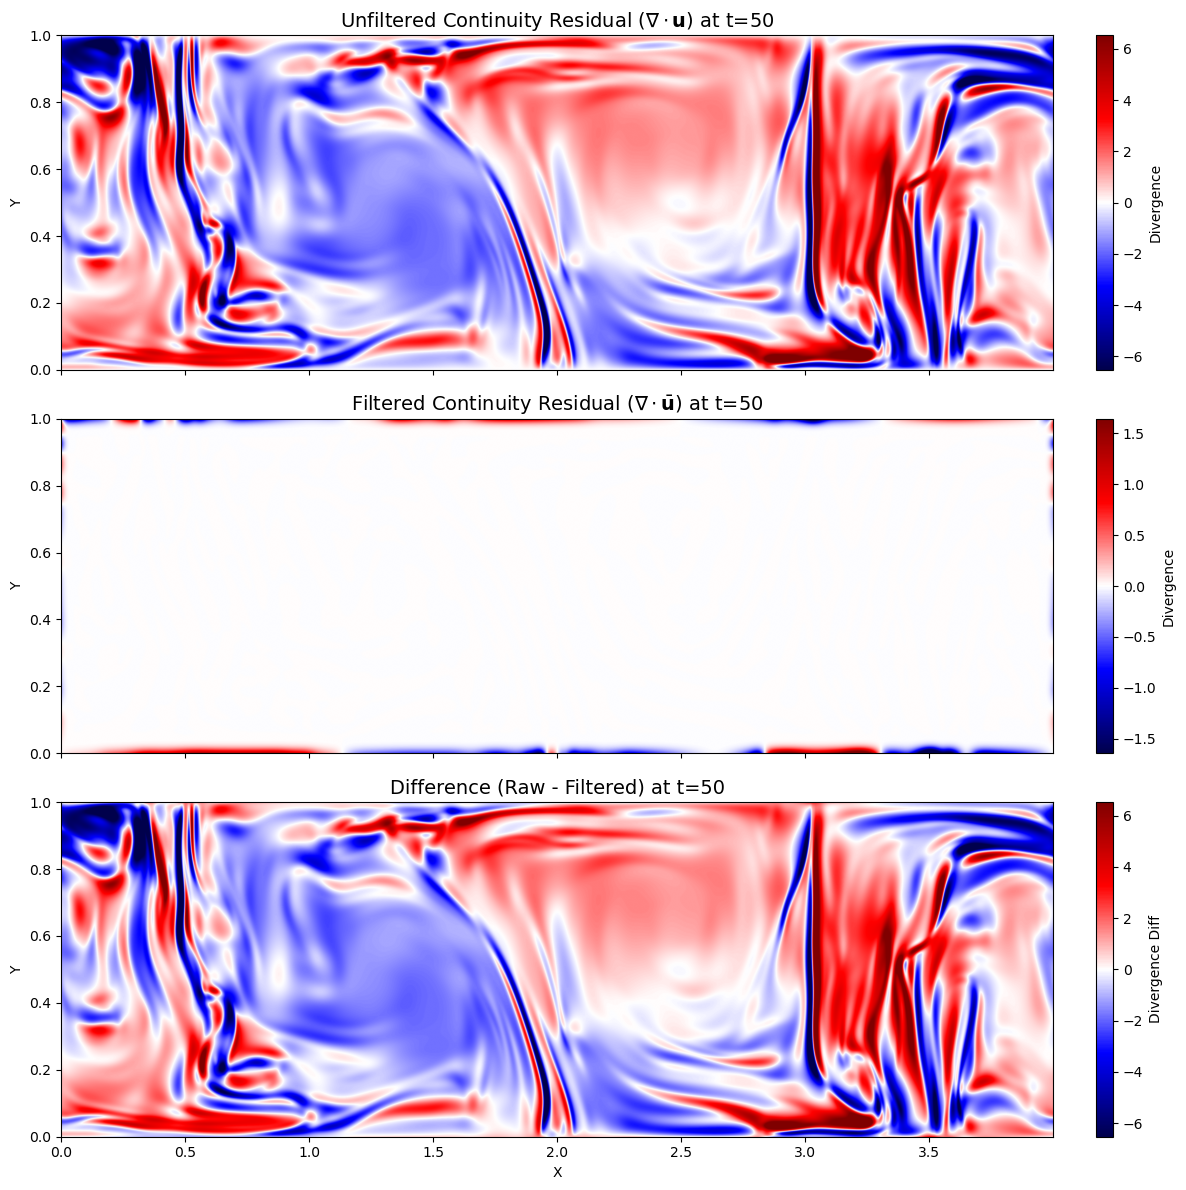

In [37]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residuals (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(V_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(U_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw

# --- 2. Filtered Divergence ---
# u_filt, v_filt, xp, yp are the JAX filtered & trimmed arrays
dx_filt = float(xp[1] - xp[0])
dy_filt = float(yp[1] - yp[0])

u_filt_t = u_filt[:, :, t_idx]
v_filt_t = v_filt[:, :, t_idx]

du_dx_filt = np.gradient(u_filt_t, dx_filt, axis=0)
dv_dy_filt = np.gradient(v_filt_t, dy_filt, axis=1)
div_filt = du_dx_filt + dv_dy_filt
extent_filt = [xp[0], xp[-1], yp[0], yp[-1]]

# --- 3. Difference (Raw - Filtered) ---
# To subtract them, we must crop the raw data to match the filtered trimmed domain
x_mask = (x >= xp[0]) & (x <= xp[-1])
y_mask = (y >= yp[0]) & (y <= yp[-1])

# Apply the coordinate masks to get an identically shaped cropped array
div_raw_cropped = div_raw[np.ix_(x_mask, y_mask)]

# Calculate difference
div_diff = div_raw_cropped - div_filt

print(f"Raw Divergence (Full) - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Filtered Divergence   - Mean: {np.mean(np.abs(div_filt)):.6e}, Max: {np.max(np.abs(div_filt)):.6e}")
print(f"Difference            - Mean: {np.mean(np.abs(div_diff)):.6e}, Max: {np.max(np.abs(div_diff)):.6e}")

# --- 4. 3x1 Plotting ---
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw_cropped)) * 0.5 
v_limit_filt = np.max(np.abs(div_filt)) * 0.5
v_limit_diff = np.max(np.abs(div_diff)) * 0.5

# Plot Raw (Cropped visually to match)
im1 = axes[0].imshow(
    div_raw_cropped.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)
axes[0].set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
axes[0].set_ylabel("Y")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04, label="Divergence")

# Plot Filtered
im2 = axes[1].imshow(
    div_filt.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_filt,
    vmax=v_limit_filt
)
axes[1].set_title(f"Filtered Continuity Residual ($\\nabla \\cdot \\bar{{\\mathbf{{u}}}}$) at t={t_idx}", fontsize=14)
axes[1].set_ylabel("Y")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04, label="Divergence")

# Plot Difference
im3 = axes[2].imshow(
    div_diff.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_filt,
    aspect='auto',
    vmin=-v_limit_diff,
    vmax=v_limit_diff
)
axes[2].set_title(f"Difference (Raw - Filtered) at t={t_idx}", fontsize=14)
axes[2].set_ylabel("Y")
axes[2].set_xlabel("X")
plt.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04, label="Divergence Diff")

plt.tight_layout()
plt.show()

In [38]:
print(np.mean(u_filt), np.mean(v_filt))

3.008161202570671e-05 1.281911401503247e-06


In [39]:
print("omega:", np.mean(np.sqrt(w_filt**2)))
# Calculate RMS for both raw and filtered divergence
rms_div_raw = np.sqrt(np.mean(div_raw**2))
rms_div_filt = np.sqrt(np.mean(div_filt**2))

print(f"RMS Divergence (Raw):      {rms_div_raw:.6e}")
print(f"RMS Divergence (Filtered): {rms_div_filt:.6e}")

omega: 2.701274435287046
RMS Divergence (Raw):      2.158629e+00
RMS Divergence (Filtered): 1.127471e-01


In [40]:
print(phi.shape)

(3996, 1436, 101, 2)


In [41]:
#%%prun # profiling
#print(P.shape)
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) #?
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
Tobs = Observable(string='T', rank=2, can_commute_indices = True, antisymmetric = False)
fobs = Observable(string='ϕ', rank=1)
observables = [uobs, bobs, pobs, zobs, wobs, Tobs, fobs]#bobszobs

z = np.full(b_filt.shape, 1)
x = np.full(b_filt.shape, 0)
unit_vect = np.concatenate([z[:, :, :, np.newaxis], x[:, :, :, np.newaxis]], axis=3)
data_dict = {'u' : u_bar, 'b' : b_filt, 'p' : p_filt, 'z̄' : unit_vect, 'w' : w_filt, 'T' : tau, 'ϕ' : phi}
print(u_filt.shape)
# fix random seed
np.random.seed(1)

world_size = np.array(p_filt.shape)
pad = 0

# fix random seed
np.random.seed(1)

dxs = [dx, dy, dt]

# initial setup of dataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())
                #irreps=(0, 1, 2))

# initialize libraries, domains, and weights
#srd.make_libraries(max_complexity=4, max_observables=3)
srd.make_libraries(max_complexity=3)

(4096, 1536, 101)


In [42]:
remove_terms = {
    "z̄_β · ∂α z̄_β",
    "∂t b · z̄_α",
    "z̄_α · z̄_β · z̄_β",
    "z̄_β · z̄_β · ϕ_α",
    "z̄_β · ∂α z̄_β",
    "∂α z̄_β"
}

def is_unwanted(t):
    return (str(t) in remove_terms)

for irrep in srd.irreps:
    lib = srd.libs[irrep]
    original_len = len(lib.terms)
    
    # Filter the terms
    lib.terms = [t for t in lib.terms if not is_unwanted(t)]
    
    new_len = len(lib.terms)
    print(f"Irrep {irrep}: Removed {original_len - new_len} terms. Remaining: {new_len}")
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Logical cores (including hyperthreading)
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")
Ndomainz = len(srd.libs[srd.irreps[1]].terms)*10
num_processorz = num_cores - 4
Ndomainz_rounded = num_processorz * round(Ndomainz / num_processorz)
print(len(srd.libs[srd.irreps[1]].terms))
print(num_processorz)
print(Ndomainz_rounded)
dom_width = 64 #scale for res
dom_time = 10 #previously 20 (without interpolation)
pad = 0
srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time*10) # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)  # or whatever number of cores you want
'''
dom_width = 64 #previously 64 - smaller world size -> smaller domain??
dom_time = 20 #previously 20 (without interpolation)
print(len(srd.libs[srd.irreps[3]].terms))
srd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)
#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=12, qmax=0)


print(Lt)
L = dom_width
T = dom_time
#print(NLt)
print(L, T)

srd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False)'''

Irrep Rank 0: Removed 0 terms. Remaining: 99
Rank 0 : 99
Irrep Rank 1: Removed 4 terms. Remaining: 124
Rank 1 : 124
Irrep Antisymmetric rank 2: Removed 1 terms. Remaining: 44
Antisymmetric rank 2 : 44
Irrep Symmetric trace-free rank 2: Removed 1 terms. Remaining: 64
Symmetric trace-free rank 2 : 64
Logical CPU cores available: 192
124
188
1316


'\ndom_width = 64 #previously 64 - smaller world size -> smaller domain??\ndom_time = 20 #previously 20 (without interpolation)\nprint(len(srd.libs[srd.irreps[3]].terms))\nsrd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)\n#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)\nsrd.make_weights(m=12, qmax=0)\n\n\nprint(Lt)\nL = dom_width\nT = dom_time\n#print(NLt)\nprint(L, T)\n\nsrd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices\nsrd.make_library_matrices(debug=False)'

In [ ]:
from commons_identify_models import *
import copy
 
libs = srd.libs
 
# Parameter ranges for different aspects of the regression process
threshold_values = [1e-7]
initializer_methods = ['power'] #  'power', 
residual_types = ['matrix_relative']
threshold_types = ['information'] # Added 'information' type , 'jump'
 
# Iterate through all combinations
for mk in range(5, 40):
    print("###############################################################k = " + str(mk) + "########################################")
    for threshold_loop in threshold_values:
        for init_method in initializer_methods:
            for res_type in residual_types:
                for thres_type in threshold_types:
                    print("-----------------------------------------------------------")
                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_type}")
                    reg_opts_list = []
                    for irrep in srd.irreps:
                        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.75)
                        init = Initializer(method=init_method, start_k=mk)
                        if res_type == "dominant_balance":
                            res = Residual(residual_type='dominant_balance')
                        else:
                            res = Residual(residual_type='matrix_relative')
     
                        iterator = ModelIterator(max_k=mk, backward_forward=False, max_passes=30)
                        if thres_type == "jump":
                            thres = Threshold(threshold_type='jump', gamma=2, delta=1e-6)
                        else:  # 'information'
                            thres = Threshold(threshold_type='information', ic=AIC)
     
                        opts = {
                            'scaler': scaler,
                            'initializer': init,
                            'residual': res,
                            'model_iterator': iterator,
                            'threshold': thres,
                            'verbose': False,
                            'inhomog': False,
                            'inhomog_col': None
                        }
                        reg_opts_list.append(opts)
                    try:
                        eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify(
                            [libs[i] for i in srd.irreps], reg_opts_list, threshold=threshold_loop, experimental=True)
                    except TypeError as e:
                        print(f"Encountered an error: {e}")

In [49]:
reg_opts_list = []
for irrep in srd.irreps:
    # for regression we need to construct Scaler, Initializer, ModelIterator, and Threshold objects
    scaler = Scaler(sub_inds=None, char_sizes=srd.libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.8)
    # the Scaler deals with nondimensionalization of the library matrix
    # sub_inds=None: (initially) retain all of the columns in the library
    # char_sizes: nondimensionalization of each column by its characteristic size
    # row_norms: rescaling of the rows of the library matrix, if supplied
    # unit_rows=True: independently normalize each row to O(1)
    # train_fraction=0.8: train/test split of 0.8 to 0.2

    # the Initializer declares the method for initializing the initial guess for the solution
    # and the ModelIterator sets options for the greedy backward-forward regression iteration
    # try a few different combinations!

    # option 1: compute initial k=10 guess via truncated inverse iteration
    init = Initializer(method='power', start_k=10) 
    # complete up to 3 backward-forward passes over 1<=k<=10
    iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 2: compute initial guess by combinatorial search over all 2-term relations
    #init = Initializer(method='combinatorial', start_k=2)
    #iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=3) 

    # option 3: include all terms in the initial guess support
    #init = Initializer(method='combinatorial', start_k=len(srd.libs[irrep].terms))
    # complete only one backward elimination pass
    #iterator = ModelIterator(max_k=len(srd.libs[irrep].terms), backward_forward=False, max_passes=1)

    # the Residual object represents the residual type used for quantifying solution accuracy
    res = Residual(residual_type='matrix_relative') # Frobenius residual
    # other options: 'absolute' residual, 'hybrid' (used for error reporting only, Frobenius used for support selection),
    # and 'dominant balance' (dominant term residual)

    # the Threshold is used for selecting the final sparsity of the relation; we provide two examples here:
    # jump criterion: gamma=1.5, and continue to remove terms until r>delta
    # setting n_terms will fix k
    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-8, n_terms=None)
    # information criterion
    #thres = Threshold(threshold_type='information', ic=AIC)
    
    # put everything together into an options dictionary
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,
            'model_iterator': iterator, 'threshold': thres}
    opts['verbose'] = False # setting to True outputs all of the debug info
    # setting to True and specifying a column number will perform inhomogeneous regression with
    # that column on the right-hand side
    opts['inhomog'] = False 
    opts['inhomog_col'] = None
    reg_opts_list.append(opts)

# now we can run the regression
eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([srd.libs[i] for i in srd.irreps], 
reg_opts_list, threshold=1e-7, report_accuracy=True)
# threshold is the max residual threshold (r_max) at which equations are accepted
# report_accuracy reports the hybrid residual r_h as well
# additional options: max_equations - halt once max_equations have been output

--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 1 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 2 ---
[0.03 s]
Identified model: ∂α z̄_α = 0 (order 2, train res 2.62e-13, test res 2.58e-13)
(r_h = 1.00e+00)
--- WORKING ON LIBRARY WITH IRREP Rank 1 AT COMPLEXITY 2 ---
[0.03 s]
Identified model: ∂t z̄_α = 0 (order 2, train res 1.89e-12, test res 1.79e-12)
(r_h = 1.00e+00)
--- WORKING ON LIBRARY WITH IRREP Antisymmetric rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Symmetric trace-free rank 2 AT COMPLEXITY 2 ---
--- WORKING ON LIBRARY WITH IRREP Rank 0 AT COMPLEXITY 3 ---
[0.14 s]
Identified model: ∂t ∂α u_α = 0 (order 3, train res 4.71e-10, test res 1.70e-09)
(r_h = 5.77e-17)
[0.24 s]
Identified model: w + -1 · w · z̄_α · z̄_α = 0 (order 3

In [ ]:
lib3 = srd.libs[srd.irreps[1]]
for idx, term in enumerate(lib3.terms):
    if str(term) == "∂t u_α":#"∂t u_α    u_β · ∂β u_α   ∂t b": #"b · z̄_α"
        print(f"Found at index {idx}: {term}") 
print(srd.libs)

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,5):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 31 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,7):

    max_kk = 6

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='power', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 85 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])

    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,7):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 22 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])

    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 56 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
print("a")

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='power', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 45 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 45 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
 
def compute_derivatives_and_residuals(u, v, p, b, tau, x, y, dt, kappa):
    """
    Computes terms of the momentum equations using np.gradient (central difference).
    Returns the residuals for U and V momentum equations.
    """
    print("Computing derivatives...")
    # Grid Spacing
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    # --- 1. Temporal Derivative (d/dt) ---
    # axis=2 is time
    u_t = np.gradient(u, dt, axis=2)
    v_t = np.gradient(v, dt, axis=2)
    # --- 2. Spatial Derivatives (First Order) ---
    # axis=0 is X, axis=1 is Y
    u_x = np.gradient(u, dx, axis=0)
    u_y = np.gradient(u, dy, axis=1)
    v_x = np.gradient(v, dx, axis=0)
    v_y = np.gradient(v, dy, axis=1)
    p_x = np.gradient(p, dx, axis=0)
    p_y = np.gradient(p, dy, axis=1)
    # --- 3. Viscous Terms (Laplacian) ---
    u_xx = np.gradient(u_x, dx, axis=0)
    u_yy = np.gradient(u_y, dy, axis=1)
    lap_u = u_xx + u_yy
    v_xx = np.gradient(v_x, dx, axis=0)
    v_yy = np.gradient(v_y, dy, axis=1)
    lap_v = v_xx + v_yy
    # --- 4. Subgrid Stress Divergence (div Tau) ---
    # tau shape: (Nx, Ny, Nt, 2, 2) -> (xx, xy; yx, yy)
    tau_xx = tau[..., 0, 0]
    tau_xy = tau[..., 0, 1]
    tau_yy = tau[..., 1, 1]
    # div(Tau)_x = d(tau_xx)/dx + d(tau_xy)/dy
    dtxx_dx = np.gradient(tau_xx, dx, axis=0)
    dtxy_dy = np.gradient(tau_xy, dy, axis=1)
    div_tau_x = dtxx_dx + dtxy_dy
    # div(Tau)_y = d(tau_xy)/dx + d(tau_yy)/dy
    dtxy_dx = np.gradient(tau_xy, dx, axis=0)
    dtyy_dy = np.gradient(tau_yy, dy, axis=1)
    div_tau_y = dtxy_dx + dtyy_dy
 
    # --- 5. Assemble Residuals ---
    # U-Momentum: du/dt + u*du/dx + v*du/dy = -dp/dx + nu*Lap(u) - div(Tau)_x
    # Residual = LHS - RHS
    # Note: If tau is defined as (Mean(uu) - Mean(u)Mean(u)), it sits on the RHS with a negative sign
    # as usually written in LES: d_t u_bar + div(u_bar u_bar) = ... - div(tau)
    adv_u = (u * u_x) + (v * u_y)
    # Res_U = Time + Advection + Pressure - Diffusion + Div(Tau)
    # Signs depend on how you move terms. Here we calculate:
    # Error = (Time + Advec) - (Pressure + Diffusion + Stress)
    # Check signs: Pressure is usually -dp/dx. Diffusion is +nu*Lap.
    # Standard Form: du/dt + u.grad(u) = -grad(p) + nu*Lap(u) - div(tau)
    # So: Res = (du/dt + u.grad(u)) - (-grad(p) + nu*Lap(u) - div(tau))
    Res_U = (u_t + adv_u) - (-p_x + kappa * lap_u - div_tau_x)
    # V-Momentum: dv/dt + u*dv/dx + v*dv/dy = -dp/dy + nu*Lap(v) + Buoyancy - div(Tau)_y
    # Buoyancy term usually +b (or T) in vertical direction
    adv_v = (u * v_x) + (v * v_y)
    Res_V = (v_t + adv_v) - (-p_y + kappa * lap_v + b - div_tau_y)
    return Res_U, Res_V
 
# --- EXECUTION ---

print("Calculating Residuals...")

# Unpack your variables
# u_bar shape is (Nx, Ny, Nt, 2)
_u = u_bar[..., 0]
_v = u_bar[..., 1]
_p = p_filt
_b = b_filt

# FIX: Use 'xp' and 'yp' (the actual filtered coordinates) instead of 'x' and 'y'
# 'x' and 'y' might have been overwritten by the SRDataset cell
res_u, res_v = compute_derivatives_and_residuals(_u, _v, _p, _b, tau, xp, yp, dt, kappa)

print("Calculation Complete.")
print(f"Residual U - Mean: {np.mean(np.abs(res_u)):.6f}, Max: {np.max(np.abs(res_u)):.6f}")
print(f"Residual V - Mean: {np.mean(np.abs(res_v)):.6f}, Max: {np.max(np.abs(res_v)):.6f}")

# --- PLOTTING ---
t_idx = 50

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])

im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])

plt.show()
 
# --- PLOTTING ---
# Visualize the error at a specific timestep
t_idx = 50
 
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
 
im1 = ax[0].imshow(res_u[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
plt.colorbar(im1, ax=ax[0])
 
im2 = ax[1].imshow(res_v[:, :, t_idx].T, origin='lower', cmap='seismic', aspect='auto')
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
plt.colorbar(im2, ax=ax[1])
 
plt.show()

In [ ]:
# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()# --- PLOTTING (To-Scale) ---
t_idx = 50

# 1. Define the physical bounds of your trimmed domain
# extent = [x_min, x_max, y_min, y_max]
extent = [xp[0], xp[-1], yp[0], yp[-1]]

# 2. Adjust figure size to accomodate the 4:1 aspect ratio
# We have two plots side-by-side. 
# If each is 4 wide x 1 high, we need a wide figure.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True) 
# Note: I changed to 2 rows, 1 column (stacked) because 4:1 plots 
# look better stacked than side-by-side on a standard screen.

# --- Plot U Residual ---
# aspect='equal' ensures physical scaling
im1 = ax[0].imshow(
    res_u[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal' 
)
ax[0].set_title(f"U-Momentum Residual (t={t_idx})")
ax[0].set_ylabel("Y")
plt.colorbar(im1, ax=ax[0], fraction=0.046, pad=0.04)

# --- Plot V Residual ---
im2 = ax[1].imshow(
    res_v[:, :, t_idx].T, 
    origin='lower', 
    cmap='seismic', 
    extent=extent, 
    aspect='equal'
)
ax[1].set_title(f"V-Momentum Residual (t={t_idx})")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("X")
plt.colorbar(im2, ax=ax[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()